<a href="https://colab.research.google.com/github/MNMARQUES/Arquitetura_MachineLearning/blob/main/Projeto2/ARQ_ML_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
# ============================================================
# PROJETO: CLASSIFICAÇÃO DE FAKE NEWS COM DEEP LEARNING
# Curso: Arquiteto(a) de Machine Learning
# Módulo 2: Processamento de Linguagem Natural
# Ambiente: Google Colab
# Arquitetura: Embedding + LSTM + Dense
# ============================================================

# 1. IMPORTAÇÃO DAS BIBLIOTECAS
import os
import re
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import tensorflow as tf
import pandas as pd
import os


from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")


In [29]:
# Reprodutibilidade
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. CAMINHOS DOS ARQUIVOS
PASTA = "/content/sample_data"

ARQUIVO_TREINO = os.path.join(PASTA, "train.csv")
ARQUIVO_TESTE = os.path.join(PASTA, "test.csv")
ARQUIVO_SUBMISSAO = os.path.join(PASTA, "submit.csv")

for arquivo in [ARQUIVO_TREINO, ARQUIVO_TESTE, ARQUIVO_SUBMISSAO]:
    if not os.path.exists(arquivo):
        raise FileNotFoundError(f"Arquivo não encontrado: {arquivo}")

print("Arquivos encontrados com sucesso!")
print(ARQUIVO_TREINO)

Arquivos encontrados com sucesso!
/content/sample_data/train.csv


In [30]:
# 3. CARREGAMENTO DOS DADOS
# Adicionamos quoting=3 (csv.QUOTE_NONE) para que o pandas ignore aspas problemáticas e não cause o erro de EOF
df = pd.read_csv(ARQUIVO_TREINO, encoding="utf-8", quoting=3, on_bad_lines='skip')


df_teste_original = pd.read_csv(
    ARQUIVO_TESTE, encoding="utf-8"
)

df_submissao = pd.read_csv(
    ARQUIVO_SUBMISSAO, encoding="utf-8"
)


In [31]:

print("\nDimensões dos arquivos:")
print("Treinamento:", df.shape)
print("Teste:", df_teste_original.shape)
print("Submissão:", df_submissao.shape)

print("\nColunas do treinamento:")
print(df.columns.tolist())



Dimensões dos arquivos:
Treinamento: (39267, 5)
Teste: (5200, 4)
Submissão: (5200, 2)

Colunas do treinamento:
['id', 'title', 'author', 'text', 'label']


In [32]:

# Verifica se o CSV foi interpretado corretamente
colunas_obrigatorias = {"title", "label"}

if not colunas_obrigatorias.issubset(df.columns):
    raise ValueError(
        "O CSV não contém as colunas esperadas 'title' e 'label'. "
        f"Colunas encontradas: {df.columns.tolist()}. "
        "Verifique o delimitador e a integridade do arquivo."
    )

In [33]:
# 4. INSPEÇÃO INICIAL
print("\nPrimeiras linhas:")
display(df.head())

print("\nTipos de dados:")
print(df.dtypes)

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nDistribuição original dos rótulos:")
print(df["label"].value_counts(dropna=False))


Primeiras linhas:


,,id,title,author,text,label
0,House Dem Aide: We Didn’t Even See Comey’s Letter Until Jason Chaffetz Tweeted It,Darrell Lucus,"""House Dem Aide: We Didn’t Even See Comey’s Le...",2016 Subscribe Jason Chaffetz on the stump in...,Utah ( image courtesy Michael Jolley,available under a Creative Commons-BY license)
With apologies to Keith Olbermann,there is no doubt who the Worst Person in The World is this week–FBI Director James Comey. But according to a House Democratic aide,it looks like we also know who the second-wor...,the ranking Democrats on the relevant committ...,NaN,NaN,NaN
As we now know,Comey notified the Republican chairmen and Democratic ranking members of the House Intelligence,Judiciary,and Oversight committees that his agency was ...,Oversight Committee Chairman Jason Chaffetz s...,"""""The FBI has learned of the existence of ema...",NaN
— Jason Chaffetz (@jasoninthehouse) October 28,2016,NaN,NaN,NaN,NaN,NaN
Of course,we now know that this was not the case . Comey was actually saying that it was reviewing the emails in light of “an unrelated case”–which we now know to be Anthony Weiner’s sexting with a teenager. But apparently such little things as facts didn’t matter to Chaffetz. The Utah Republican had already vowed to initiate a raft of investigations if Hillary wins–at least two years’ worth,and possibly an entire term’s worth of them. ...,NaN,NaN,NaN,NaN



Tipos de dados:
id        object
title     object
author    object
text      object
label     object
dtype: object

Valores ausentes:
id        19765
title     25941
author    31569
text      35379
label     37747
dtype: int64

Distribuição original dos rótulos:
label
NaN                                                                                                                                                           37747
1                                                                                                                                                               161
 2016                                                                                                                                                            31
 2016 Share This                                                                                                                                                  5
 etc.                                                                     

In [34]:
# 5. LIMPEZA DOS DADOS
# O modelo precisa de texto e rótulo para aprender.
# O texto do título será utilizado, seguindo a proposta do notebook.

df = df.dropna(subset=["title", "label"]).copy()

df["title"] = df["title"].astype(str).str.strip()

df = df[df["title"] != ""]

# Forçar a conversão de label para numérico e filtrar apenas valores binários válidos (0 ou 1)
df["label"] = pd.to_numeric(df["label"], errors="coerce")
df = df.dropna(subset=["label"]).copy()

# Mantém apenas as linhas onde label é 0 ou 1
df = df[df["label"].isin([0, 1, 0.0, 1.0])]
df["label"] = df["label"].astype("int32")

if df["label"].nunique() != 2:
    raise ValueError(
        "O conjunto precisa conter as duas classes: 0 e 1."
    )


In [36]:
print("\nDimensões após a limpeza:", df.shape)
print("\nDistribuição das classes:")
print(df["label"].value_counts())


Dimensões após a limpeza: (162, 5)

Distribuição das classes:
label
1    160
0      2
Name: count, dtype: int64


In [37]:
# Convenção do dataset:
# 0 = notícia considerada verdadeira
# 1 = notícia considerada falsa

# 6. DEFINIÇÃO DAS VARIÁVEIS INDEPENDENTE E DEPENDENTE
X = df["title"].reset_index(drop=True)
y = df["label"].reset_index(drop=True)

print("\nFormato de X:", X.shape)
print("Formato de y:", y.shape)


Formato de X: (162,)
Formato de y: (162,)


In [38]:
# 7. DOWNLOAD DOS RECURSOS DE NLP
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()

In [39]:
# 8. PRÉ-PROCESSAMENTO DOS TEXTOS
def preprocessar_texto(texto):
    texto = str(texto).lower()

    # Mantém letras e espaços
    texto = re.sub(r"[^a-z\s]", " ", texto)

    # Divide o texto em palavras
    palavras = texto.split()

    # Remove stopwords e aplica stemming
    palavras = [
        stemmer.stem(palavra)
        for palavra in palavras
        if palavra not in stop_words
    ]

    return " ".join(palavras)

corpus = X.apply(preprocessar_texto).tolist()

print("\nExemplo de texto original:")
print(X.iloc[0])

print("\nExemplo de texto processado:")
print(corpus[0])


Exemplo de texto original:
the notion that the United States would throw Israel under the bus and allow those who engage in despotism and blatant anti-Semitism to have a say on Israel’s fate

Exemplo de texto processado:
notion unit state would throw israel bu allow engag despot blatant anti semit say israel fate


In [40]:
# 9. TOKENIZAÇÃO E REPRESENTAÇÃO NUMÉRICA
# Vocabulário limitado às 5.000 palavras mais frequentes.

VOCAB_SIZE = 5000
MAX_LENGTH = 100

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(corpus)

sequencias = tokenizer.texts_to_sequences(corpus)

X_padded = pad_sequences(
    sequencias,
    maxlen=MAX_LENGTH,
    padding="pre",
    truncating="pre"
)

X_final = np.array(X_padded, dtype=np.int32)
y_final = np.array(y, dtype=np.int32)

print("\nFormato dos textos tokenizados:", X_final.shape)
print("Formato dos rótulos:", y_final.shape)
print("\nExemplo de sequência numérica:")
print(X_final[0])


Formato dos textos tokenizados: (162, 100)
Formato dos rótulos: (162,)

Exemplo de sequência numérica:
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0 218  69  26  16 219  70
 220  71 221 222 223  49 110 111  70 224]


In [41]:
# 10. DIVISÃO ENTRE TREINO E VALIDAÇÃO
X_train, X_val, y_train, y_val = train_test_split(
    X_final,
    y_final,
    test_size=0.15,
    random_state=SEED,
    stratify=y_final
)

print("\nDimensões dos conjuntos:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)


Dimensões dos conjuntos:
X_train: (137, 100)
y_train: (137,)
X_val: (25, 100)
y_val: (25,)


In [42]:
# 11. CONSTRUÇÃO DA REDE NEURAL LSTM
EMBEDDING_DIM = 40
LSTM_UNITS = 100

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),
    LSTM(LSTM_UNITS),
    Dense(1, activation="sigmoid")
])

# Entropia cruzada binária é apropriada para classificação binária
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nResumo da arquitetura:")
model.summary()


Resumo da arquitetura:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [43]:
# 12. TREINAMENTO
EPOCHS = 10
BATCH_SIZE = 64

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)


Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 191ms/step - accuracy: 0.7956 - loss: 0.6808 - val_accuracy: 1.0000 - val_loss: 0.6116
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9854 - loss: 0.5934 - val_accuracy: 1.0000 - val_loss: 0.4270
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9854 - loss: 0.3928 - val_accuracy: 1.0000 - val_loss: 0.1146
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - accuracy: 0.9854 - loss: 0.1303 - val_accuracy: 1.0000 - val_loss: 0.0226
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.9854 - loss: 0.0797 - val_accuracy: 1.0000 - val_loss: 0.0160
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9854 - loss: 0.0761 - val_accuracy: 1.0000 - val_loss: 0.0181
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9854 - loss: 0.0756 - val_accuracy: 1.0000 - val_loss: 0.0235
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9854 - loss: 0.0771 - val_accuracy: 1.0000 - val_loss: 0.0313

In [44]:
# 13. AVALIAÇÃO DO MODELO
loss, accuracy = model.evaluate(
    X_val,
    y_val,
    verbose=0
)

print("\n========== RESULTADOS ==========")
print(f"Loss de validação: {loss:.4f}")
print(f"Acurácia de validação: {accuracy * 100:.2f}%")


========== RESULTADOS ==========
Loss de validação: 0.0487
Acurácia de validação: 100.00%


In [45]:
# 14. GERAÇÃO DAS PREVISÕES
probabilidades = model.predict(
    X_val,
    verbose=0
).ravel()

# Limiar de decisão de 0,5
y_pred = (probabilidades >= 0.5).astype(int)

acc = accuracy_score(y_val, y_pred)

print(f"\nAcurácia calculada: {acc * 100:.2f}%")

print("\nRelatório de classificação:")
print(
    classification_report(
        y_val,
        y_pred,
        labels=[0, 1],
        target_names=["Não Fake News", "Fake News"],
        zero_division=0
    )
)


Acurácia calculada: 100.00%

Relatório de classificação:
               precision    recall  f1-score   support

Não Fake News       0.00      0.00      0.00         0
    Fake News       1.00      1.00      1.00        25

     accuracy                           1.00        25
    macro avg       0.50      0.50      0.50        25
 weighted avg       1.00      1.00      1.00        25



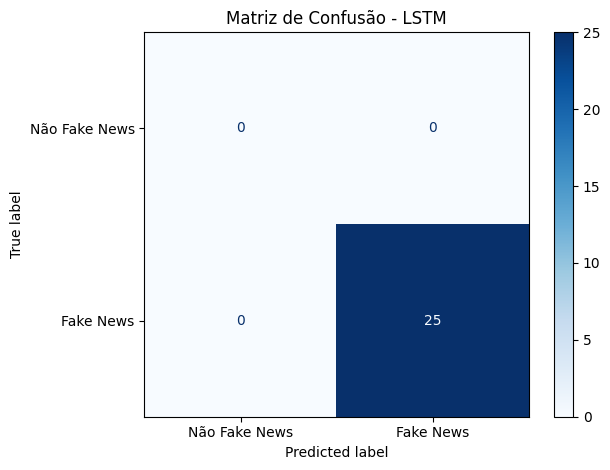

In [46]:
# 15. MATRIZ DE CONFUSÃO
cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Não Fake News", "Fake News"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - LSTM")
plt.tight_layout()
plt.show()

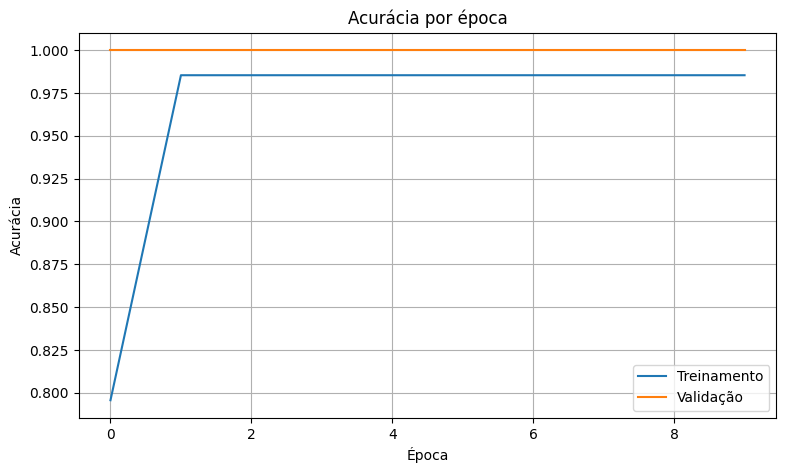

In [47]:
# 16. GRÁFICO DE ACURÁCIA
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Treinamento"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validação"
)

plt.title("Acurácia por época")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True)

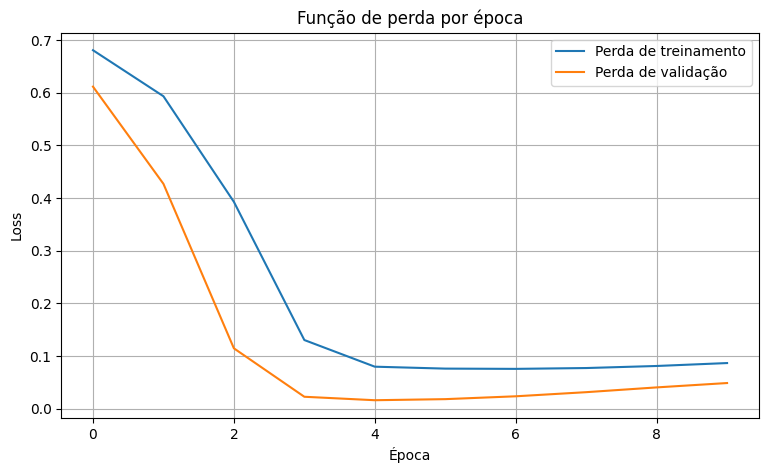

In [48]:
# 17. GRÁFICO DA FUNÇÃO DE PERDA
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Perda de treinamento"
)

plt.plot(
    history.history["val_loss"],
    label="Perda de validação"
)

plt.title("Função de perda por época")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [49]:
# 18. FUNÇÃO PARA CLASSIFICAR UM NOVO TEXTO
def classificar_noticia(texto):
    texto_processado = preprocessar_texto(texto)

    sequencia = tokenizer.texts_to_sequences(
        [texto_processado]
    )

    sequencia_padded = pad_sequences(
        sequencia,
        maxlen=MAX_LENGTH,
        padding="pre",
        truncating="pre"
    )

    prob_fake = float(
        model.predict(sequencia_padded, verbose=0)[0][0]
    )

    classe = 1 if prob_fake >= 0.5 else 0

    resultado = (
        "Fake News"
        if classe == 1
        else "Não Fake News"
    )

    return {
        "classificacao": resultado,
        "probabilidade_fake_news": round(prob_fake, 4),
        "probabilidade_nao_fake_news": round(1 - prob_fake, 4)
    }

# Exemplo de utilização
exemplo = str(X.iloc[0])

print("\n========== EXEMPLO DE PREDIÇÃO ==========")
print("Título:", exemplo)
print(classificar_noticia(exemplo))

print("\nProjeto executado até a etapa de avaliação.")


========== EXEMPLO DE PREDIÇÃO ==========
Título: the notion that the United States would throw Israel under the bus and allow those who engage in despotism and blatant anti-Semitism to have a say on Israel’s fate
{'classificacao': 'Fake News', 'probabilidade_fake_news': 0.9527, 'probabilidade_nao_fake_news': 0.0473}

Projeto executado até a etapa de avaliação.
